# 05 · k-Nearest Neighbours

k-NN predicts a new point from the *k* closest training points, which vote
(classification) or average (regression). No training phase, no optimizer — the
model stores the labelled data and works at prediction time.

Distance-based, so sensitive to feature scale — see the scaling in
[`01_preprocessing`](01_preprocessing.ipynb). Features here are already on a
comparable scale.

## Data and a train/test split

k-NN predicts new points from stored ones, so we split into training and
held-out test sets — each its own `DolceSet`.

In [1]:
import numpy as np
import polars as pl

from dolcestat.preprocessing import DolceSet
from dolcestat.neighbors import KNNClassifier, KNNRegressor

rng = np.random.default_rng(0)
n = 300
x1 = rng.normal(0, 1, n)
x2 = rng.normal(0, 1, n)
prob = 1 / (1 + np.exp(-(1.5 * x1 - 2.0 * x2 + 0.4)))
label = (rng.uniform(size=n) < prob).astype(int)
df = pl.DataFrame({"x1": x1, "x2": x2, "label": label})

order = rng.permutation(n)
train_rows, test_rows = order[:240].tolist(), order[240:].tolist()

train = DolceSet()
train.load_from_polars_dataframe(df[train_rows], target_col="label")
test = DolceSet()
test.load_from_polars_dataframe(df[test_rows], target_col="label")

## Classification

Build a `KNNClassifier` with its settings — `k`, the distance `metric`, and how
neighbours are `weights`-ed — then `fit` it on the training set (it just stores
the data) and `predict` the test set.
`predict` returns an analyzer with predicted labels (`y_fit`) and per-class
probabilities (`proba`).

In [2]:
knn = KNNClassifier(k=7, metric="euclidean", weights="distance").fit(train)
result = knn.predict(test)

print("predicted labels:", result.y_fit[:10])
print("class probabilities (first 3 rows):")
print(np.round(result.proba[:3], 2))

predicted labels: [0 1 0 1 0 0 1 0 0 0]
class probabilities (first 3 rows):
[[0.51 0.49]
 [0.08 0.92]
 [1.   0.  ]]


## The knobs

- **`k`** — how many neighbours vote. Small `k` fits tightly (low bias, high
  variance); large `k` smooths.
- **`metric`** — `"euclidean"`, `"manhattan"`, or `"minkowski"` (with
  `minkowski_p`).
- **`weights`** — `"uniform"` (every neighbour equal) or distance-based
  (`"distance"`, `"squared_distance"`, `"gaussian"`), so closer neighbours count
  for more.

The next section turns each knob and plots what changes.

In [3]:
alt = KNNClassifier(k=15, metric="manhattan", weights="uniform").fit(train).predict(test)
print("k=15, manhattan, uniform — first 10 labels:", alt.y_fit[:10])

k=15, manhattan, uniform — first 10 labels: [1 1 0 1 0 0 1 0 1 0]


## Turning the knobs

One small experiment per knob, on synthetic data where we know the truth. The maps
show the model's probability of class 1 (blue → 0, orange → 1) with its 0.5 decision
boundary in black.

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

BLUE, ORANGE = "#2a78d6", "#eb6834"  # class 0 / class 1
COLOURS = {  # the settings being compared
    "euclidean": "#6250d6", "manhattan": "#1baf7a",
    "uniform": "#6250d6", "distance": "#1baf7a", "gaussian": "#eda100",
}
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"

sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "grid.color": GRID, "axes.edgecolor": "#c3c2b7", "text.color": INK,
        "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
        "axes.titlesize": 11, "axes.titlelocation": "left",
    },
)
# blue (class 0) -> neutral -> orange (class 1), tinted so the saturated points stay readable
PROBA_CMAP = LinearSegmentedColormap.from_list("class_proba", ["#a9c8ee", "#f0efec", "#f6bca4"])


def as_set(X, y=None):
    return DolceSet.from_arrays(X, y)


def fit_predict(X_train, y_train, X_test, y_test, **knn):
    return KNNClassifier(**knn).fit(as_set(X_train, y_train)).predict(as_set(X_test, y_test))


def decision_map(ax, X, y, xlim, ylim, **knn):
    """Probability map of a k-NN fitted on (X, y), its 0.5 boundary, and the training points."""
    gx, gy = np.meshgrid(np.linspace(*xlim, 100), np.linspace(*ylim, 100))
    grid = as_set(np.column_stack([gx.ravel(), gy.ravel()]))
    p = KNNClassifier(**knn).fit(as_set(X, y)).predict(grid).proba[:, 1].reshape(gx.shape)
    bands = np.arange(-0.025, 1.026, 0.05)  # 21 bands, centred on 0, 0.05, ..., 1
    ax.contourf(gx, gy, p, levels=bands, cmap=PROBA_CMAP, norm=Normalize(0, 1))
    ax.contour(gx, gy, p, levels=[0.5], colors=INK, linewidths=1.3)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(y == 1, ORANGE, BLUE), s=16,
               edgecolors=SURFACE, linewidths=0.6, zorder=3)
    ax.set(xlim=xlim, ylim=ylim, xticks=[], yticks=[])
    ax.grid(False)


def repeat(make_data, score, settings, n_rep=15):
    """Mean and standard error of `score` for each setting over `n_rep` fresh datasets.

    make_data(rng) -> (X_train, y_train, X_test, y_test); settings maps a name to KNN kwargs.
    """
    scores = {name: [] for name in settings}
    for rep in range(n_rep):
        X_tr, y_tr, X_te, y_te = make_data(np.random.default_rng(rep))
        for name, knn in settings.items():
            scores[name].append(score(fit_predict(X_tr, y_tr, X_te, y_te, **knn)))
    return {name: (np.mean(s), np.std(s, ddof=1) / np.sqrt(n_rep)) for name, s in scores.items()}


def bar_compare(ax, results, ylabel, chance=None):
    """One bar per setting: mean ± standard error, labelled with its value."""
    for i, (name, (mean, se)) in enumerate(results.items()):
        ax.bar(i, mean, width=0.5, color=COLOURS[name])
        ax.errorbar(i, mean, yerr=se, color=INK, capsize=4, lw=1.2)
        ax.text(i, mean + se + 0.02, f"{mean:.2f}", ha="center", fontsize=10)
    if chance is not None:
        ax.axhline(chance, color=MUTED, lw=1)
        ax.text(len(results) - 0.45, chance + 0.015, "chance", ha="right", fontsize=9, color=MUTED)
    ax.set_xticks(range(len(results)), list(results))
    ax.set(xlim=(-0.6, len(results) - 0.4), ylim=(0, 1), ylabel=ylabel)
    ax.grid(axis="x", visible=False)


CLASSES = [
    Line2D([], [], marker="o", ls="", color=BLUE, mec=SURFACE, label="class 0"),
    Line2D([], [], marker="o", ls="", color=ORANGE, mec=SURFACE, label="class 1"),
]
BOUNDARY = Line2D([], [], color=INK, lw=1.3, label="k-NN decision boundary (P = 0.5)")
TRUTH = Line2D([], [], color=INK, lw=1.2, ls="--", label="true boundary")


def legend_below(fig, *extra):
    fig.legend(handles=[*CLASSES, *extra], loc="lower center", ncol=2 + len(extra), fontsize=9)

## `k`: too small, about right, too large

Class 1 lies above the wave `x2 = 1.2·sin(1.5·x1)` (dashed), with label noise. Same
200 training points, three values of `k`.

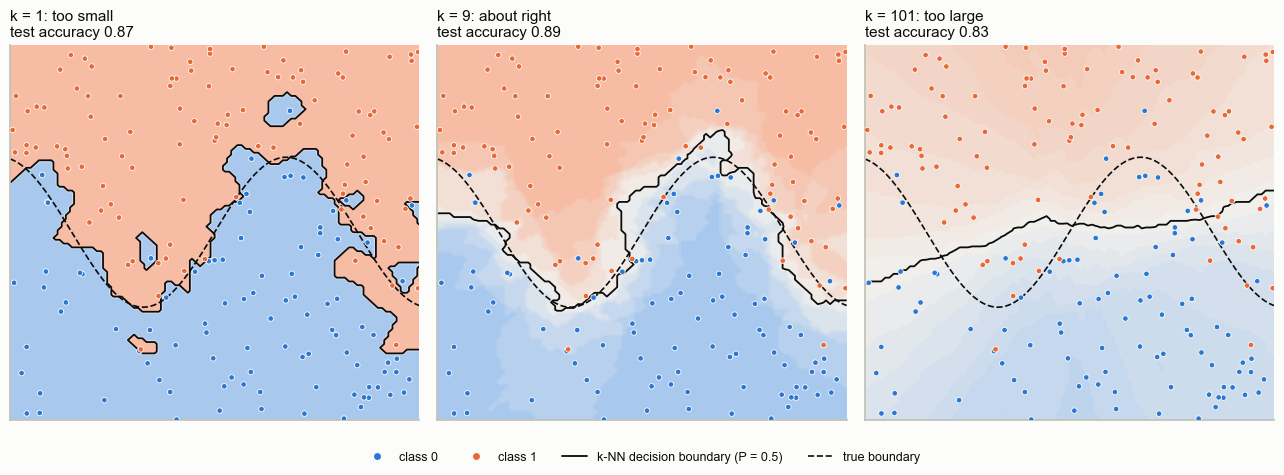

In [5]:
def true_p(X, sharpness=2.5):
    """True P(class 1 | x): above the wave x2 = 1.2·sin(1.5·x1), blurred by label noise."""
    return 1 / (1 + np.exp(-sharpness * (X[:, 1] - 1.2 * np.sin(1.5 * X[:, 0]))))


def draw_wavy(rng, n):
    X = rng.uniform(-3, 3, (n, 2))
    return X, (rng.uniform(size=n) < true_p(X)).astype(int)


LIM = (-3, 3)
wave_x = np.linspace(*LIM, 200)
wave_y = 1.2 * np.sin(1.5 * wave_x)
X_wave, y_wave = draw_wavy(np.random.default_rng(0), 200)
X_wave_test, y_wave_test = draw_wavy(np.random.default_rng(99), 2000)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, (k, verdict) in zip(axes, [(1, "too small"), (9, "about right"), (101, "too large")]):
    accuracy = fit_predict(X_wave, y_wave, X_wave_test, y_wave_test, k=k).accuracy()
    decision_map(ax, X_wave, y_wave, LIM, LIM, k=k)
    ax.plot(wave_x, wave_y, color=INK, lw=1.2, ls="--")
    ax.set_title(f"k = {k}: {verdict}\ntest accuracy {accuracy:.2f}")
legend_below(fig, BOUNDARY, TRUTH)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

- **`k = 1`** follows every noisy label: low bias, high variance.
- **`k = 101`** averages over so wide an area that the wave is flattened: high bias,
  low variance.
- **`k = 9`** balances the two.

## `metric`: when Manhattan beats Euclidean

Euclidean squares each feature's gap, so one huge gap dominates the distance;
Manhattan doesn't. Below, all 40 features lean slightly towards the true class, but
10% of the readings are glitches (large random spikes).

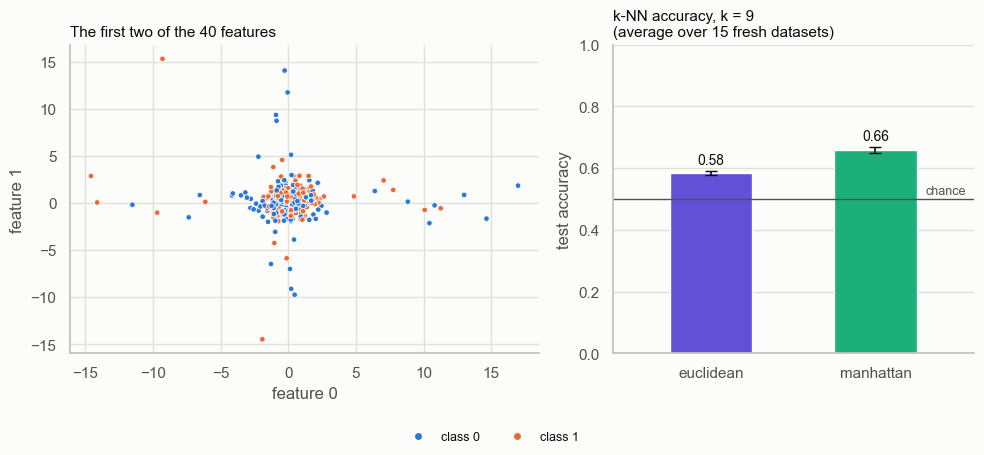

In [6]:
def weak_spiky(rng, n, n_features=40, shift=0.35, glitch_rate=0.1, glitch_sd=8):
    """Every feature leans a little towards the class; some readings are big random spikes."""
    y = rng.integers(0, 2, n)
    X = rng.normal(0, 1, (n, n_features)) + (y[:, None] - 0.5) * shift
    X += (rng.uniform(size=X.shape) < glitch_rate) * rng.normal(0, glitch_sd, X.shape)
    return X, y


X_demo, y_demo = weak_spiky(np.random.default_rng(3), 300)
results = repeat(
    lambda rng: (*weak_spiky(rng, 200), *weak_spiky(rng, 800)),
    lambda result: result.accuracy(),
    {"euclidean": dict(k=9, metric="euclidean"), "manhattan": dict(k=9, metric="manhattan")},
)

fig, (ax_data, ax_bars) = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax_data.scatter(X_demo[:, 0], X_demo[:, 1], c=np.where(y_demo == 1, ORANGE, BLUE), s=16,
                edgecolors=SURFACE, linewidths=0.6)
ax_data.set(title="The first two of the 40 features", xlabel="feature 0", ylabel="feature 1")
bar_compare(ax_bars, results, "test accuracy", chance=0.5)
ax_bars.set_title("k-NN accuracy, k = 9\n(average over 15 fresh datasets)")
legend_below(fig)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

A typical glitch adds ~64 to a squared Euclidean distance, more than the class
evidence in all 40 features together (≈ 5), so "nearest" comes to mean "least
glitched" and Euclidean is only a little above chance. Manhattan adds only ~8 per
glitch.

## `weights`: `"distance"` beats `"uniform"`

The rare class below is 10% of the data. With a generous `k`, a rare point's
neighbours are mostly majority points, so under uniform voting they outvote the few
close rare ones. `"distance"` lets the close ones count more.

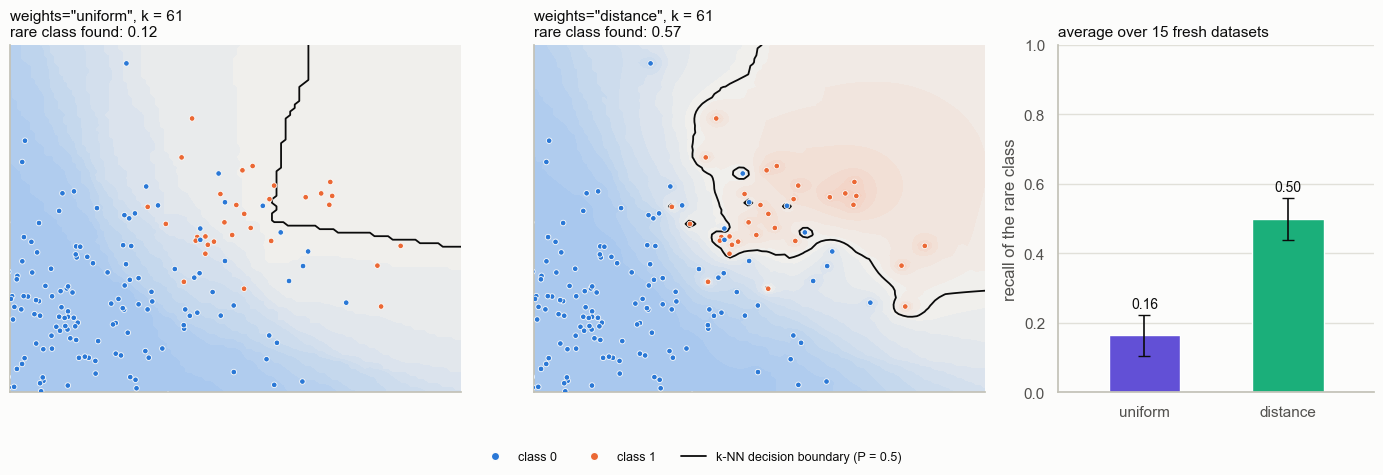

In [7]:
def rare_class(rng, n, minority_share=0.1):
    """90% of points ~ a wide blob at the origin, 10% ~ a small tight blob nearby."""
    y = (rng.uniform(size=n) < minority_share).astype(int)
    X = np.where(y[:, None] == 1, rng.normal([2.0, 1.5], 0.6, (n, 2)), rng.normal(0, 1.2, (n, 2)))
    return X, y


def rare_data(rng):
    return (*rare_class(rng, 300), *rare_class(rng, 2000))


# The maps show one of the 15 datasets averaged in the bars: the one closest to their average.
X_rare, y_rare, X_rare_test, y_rare_test = rare_data(np.random.default_rng(2))
results = repeat(
    rare_data,
    lambda result: result.recall(),  # share of the rare class that is found
    {"uniform": dict(k=61), "distance": dict(k=61, weights="distance")},
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1, 0.7]})
for ax, weights in zip(axes[:2], ("uniform", "distance")):
    recall = fit_predict(X_rare, y_rare, X_rare_test, y_rare_test, k=61, weights=weights).recall()
    decision_map(ax, X_rare, y_rare, (-0.5, 4.5), (-1, 4), k=61, weights=weights)
    ax.set_title(f'weights="{weights}", k = 61\nrare class found: {recall:.2f}')
bar_compare(axes[2], results, "recall of the rare class")
axes[2].set_title("average over 15 fresh datasets")
legend_below(fig, BOUNDARY)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Uniform voting finds little of the rare class; distance weighting finds about half of
it, and did better on every one of the 15 datasets.

## Gaussian kernel: a large `k` without the bias

`weights="gaussian"` weighs each neighbour by `exp(-d² / 2σ²)`, where `σ` is the
spread of the `k` neighbour distances. Far neighbours barely count, so a large `k`
no longer flattens the boundary. Same wavy data as above, with `k = 61`.

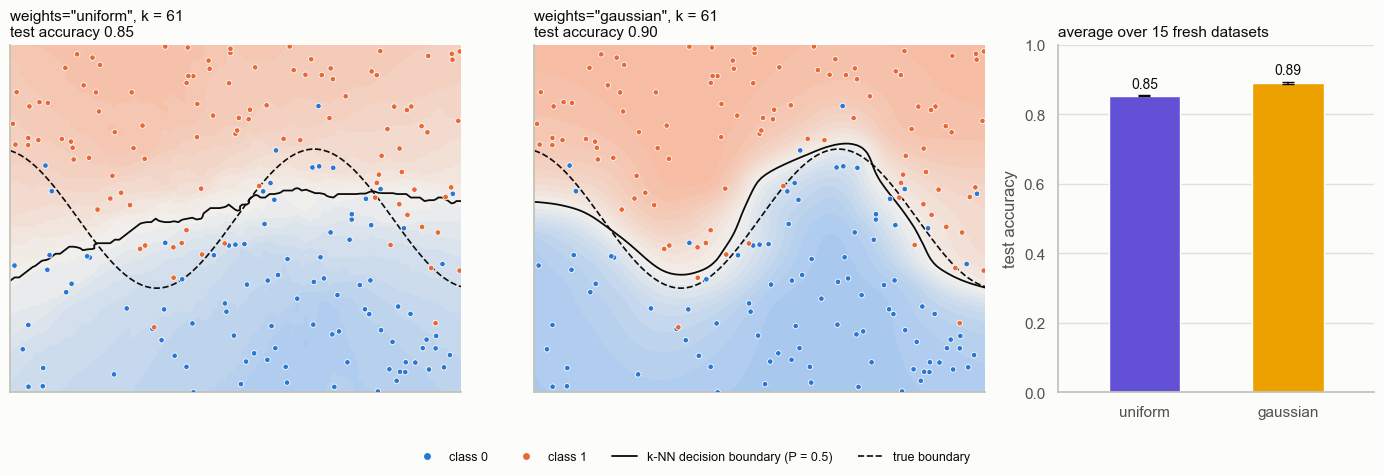

In [8]:
settings = {"uniform": dict(k=61), "gaussian": dict(k=61, weights="gaussian")}
results = repeat(
    lambda rng: (*draw_wavy(rng, 200), *draw_wavy(rng, 2000)),
    lambda result: result.accuracy(),
    settings,
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1, 0.7]})
for ax, (weights, knn) in zip(axes[:2], settings.items()):
    accuracy = fit_predict(X_wave, y_wave, X_wave_test, y_wave_test, **knn).accuracy()
    decision_map(ax, X_wave, y_wave, LIM, LIM, **knn)
    ax.plot(wave_x, wave_y, color=INK, lw=1.2, ls="--")
    ax.set_title(f'weights="{weights}", k = 61\ntest accuracy {accuracy:.2f}')
bar_compare(axes[2], results, "test accuracy")
axes[2].set_title("average over 15 fresh datasets")
legend_below(fig, BOUNDARY, TRUTH)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Uniform voting has lost the wave; the Gaussian weights keep it. Use it with a
generous `k`: with very few neighbours the bandwidth can collapse and the
probabilities come out `NaN`.

## Regression

`KNNRegressor` works the same way but **averages** neighbours' target values
(weighted, if asked).

In [9]:
rng = np.random.default_rng(1)
m = 200
a = rng.normal(0, 1, m)
b = rng.normal(0, 1, m)
target = 2.0 * a - 1.0 * b + 0.5 + rng.normal(0, 0.3, m)
rdf = pl.DataFrame({"a": a, "b": b, "target": target})

ro = rng.permutation(m)
rtrain = DolceSet()
rtrain.load_from_polars_dataframe(rdf[ro[:160].tolist()], target_col="target")
rtest = DolceSet()
rtest.load_from_polars_dataframe(rdf[ro[160:].tolist()], target_col="target")

reg_result = KNNRegressor(k=10, weights="distance").fit(rtrain).predict(rtest)
print("predicted values:", np.round(reg_result.y_fit[:6], 2))

predicted values: [ 1.47 -2.47  1.62 -2.05  2.58  1.61]


## Recap

No optimizer, no weights to learn — just neighbours and a distance. Both
`predict` calls handed back analyzers; in [`06_metrics`](06_metrics.ipynb) we
finally measure how good every model in this series actually is.